<a href="https://colab.research.google.com/github/saraaldenali5555/Machine_Learning_Training/blob/main/Training_Diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [25]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
file_path = '/content/drive/MyDrive/ML_Training/Dataset/diabetes_prediction_dataset.csv'

df = pd.read_csv(file_path)
df.info()
print("Dataset Shape:", df.shape)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   gender               100000 non-null  object 
 1   age                  100000 non-null  float64
 2   hypertension         100000 non-null  int64  
 3   heart_disease        100000 non-null  int64  
 4   smoking_history      100000 non-null  object 
 5   bmi                  100000 non-null  float64
 6   HbA1c_level          100000 non-null  float64
 7   blood_glucose_level  100000 non-null  int64  
 8   diabetes             100000 non-null  int64  
dtypes: float64(3), int64(4), object(2)
memory usage: 6.9+ MB
Dataset Shape: (100000, 9)


In [26]:
print("Dataset Shape:", df.shape)
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Shape: (100000, 9)
Number of Rows: 100000
Number of Columns: 9


In [27]:
# 1. التحقق من القيم المفقودة
missing_values = df.isnull().sum()
print("القيم المفقودة في كل عمود:")
print(missing_values)

# حذف القيم المفقودة إن وجدت
df_cleaned = df.dropna()
print(f"\nحجم البيانات بعد حذف القيم المفقودة: {df_cleaned.shape}")

# 2. التحقق من الصفوف المكررة وحذفها
duplicates_count = df_cleaned.duplicated().sum()
print(f"\nعدد الصفوف المكررة: {duplicates_count}")

df_cleaned = df_cleaned.drop_duplicates()
print(f"حجم البيانات بعد حذف القيم المكررة: {df_cleaned.shape}")

القيم المفقودة في كل عمود:
gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

حجم البيانات بعد حذف القيم المفقودة: (100000, 9)

عدد الصفوف المكررة: 3854
حجم البيانات بعد حذف القيم المكررة: (96146, 9)


In [38]:
# تحويل المتغيرات الفئوية (Categorical) إلى رقمية باستخدام Label Encoding أو Mapping المناسب
if 'gender' in df_cleaned.columns and df_cleaned['gender'].dtype == 'object':
    df_cleaned['gender'] = df_cleaned['gender'].astype('category').cat.codes

if 'smoking_history' in df_cleaned.columns and df_cleaned['smoking_history'].dtype == 'object':
    df_cleaned['smoking_history'] = df_cleaned['smoking_history'].astype('category').cat.codes

print("تم تحويل المتغيرات الفئوية بنجاح.")
df_cleaned.info()

تم تحويل المتغيرات الفئوية بنجاح.
<class 'pandas.core.frame.DataFrame'>
Index: 96146 entries, 0 to 99999
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   gender               96146 non-null  int8   
 1   age                  96146 non-null  float64
 2   hypertension         96146 non-null  int64  
 3   heart_disease        96146 non-null  int64  
 4   smoking_history      96146 non-null  int8   
 5   bmi                  96146 non-null  float64
 6   HbA1c_level          96146 non-null  float64
 7   blood_glucose_level  96146 non-null  int64  
 8   diabetes             96146 non-null  int64  
dtypes: float64(3), int64(4), int8(2)
memory usage: 6.1 MB


عدد الحالات لكل فئة:
diabetes
0    87664
1     8482
Name: count, dtype: int64

النسبة المئوية لكل فئة:
diabetes
0    91.178
1     8.822
Name: proportion, dtype: float64


/tmp/ipykernel_868/281013524.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='diabetes', data=df_cleaned, palette='Set2')


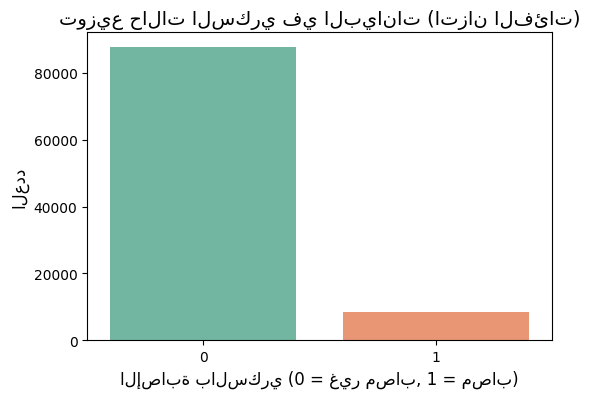

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

# حساب عدد ونسب الفئات للهدف (diabetes)
class_counts = df_cleaned['diabetes'].value_counts()
class_percentages = df_cleaned['diabetes'].value_counts(normalize=True) * 100

print("عدد الحالات لكل فئة:")
print(class_counts)
print("\nالنسبة المئوية لكل فئة:")
print(class_percentages)

# رسم توضيحي لتوزيع الفئات لتوضيح عدم الاتزان
plt.figure(figsize=(6, 4))
# استخدام الأسماء العربية في الرسم
sns.countplot(x='diabetes', data=df_cleaned, palette='Set2')
plt.title('توزيع حالات السكري في البيانات (اتزان الفئات)', fontsize=14)
plt.xlabel('الإصابة بالسكري (0 = غير مصاب, 1 = مصاب)', fontsize=12)
plt.ylabel('العدد', fontsize=12)
plt.show()

In [39]:
from sklearn.model_selection import train_test_split
from imblearn.under_sampling import RandomUnderSampler

# فصل الميزات عن الهدف
X = df_cleaned.drop(columns=['diabetes'])
y = df_cleaned['diabetes']

# تقسيم البيانات إلى تدريب واختبار أولاً
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# تطبيق تقليل العينات (Under-sampling) على بيانات التدريب فقط لتفادي تسريب البيانات
rus = RandomUnderSampler(random_state=42)
X_train_resampled, y_train_resampled = rus.fit_resample(X_train, y_train)

print("--- توزيع الفئات بعد تقليل عينات الفئة الأكثر (Under-sampling) ---")
count_0 = (y_train_resampled == 0).sum()
count_1 = (y_train_resampled == 1).sum()
total_resampled = len(y_train_resampled)

print(f"الفئة 0 (غير مصاب) بعد التقليل: العدد = {count_0:,} | النسبة = {(count_0/total_resampled)*100:.2f}%")
print(f"الفئة 1 (مصاب) دون تغيير:   العدد = {count_1:,} | النسبة = {(count_1/total_resampled)*100:.2f}%")

--- توزيع الفئات بعد تقليل عينات الفئة الأكثر (Under-sampling) ---
الفئة 0 (غير مصاب) بعد التقليل: العدد = 6,786 | النسبة = 50.00%
الفئة 1 (مصاب) دون تغيير:   العدد = 6,786 | النسبة = 50.00%


========== Naive Bayes Model ==========
Classification Report (Naive Bayes):
              precision    recall  f1-score   support

           0       0.98      0.90      0.93     17534
           1       0.41      0.77      0.54      1696

    accuracy                           0.88     19230
   macro avg       0.70      0.83      0.74     19230
weighted avg       0.93      0.88      0.90     19230

Confusion Matrix (Naive Bayes):
[[15704  1830]
 [  398  1298]]


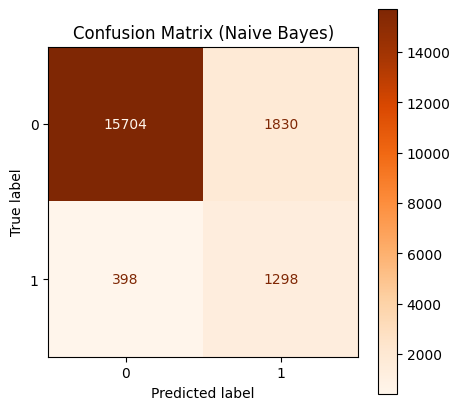

In [40]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# تدريب نموذج Naive Bayes
nb_model = GaussianNB()
nb_model.fit(X_train_resampled, y_train_resampled)

# التنبؤ على بيانات الاختبار
y_pred_nb = nb_model.predict(X_test)

# عرض التقرير
print("========== Naive Bayes Model ==========")
print("Classification Report (Naive Bayes):")
print(classification_report(y_test, y_pred_nb))

print("Confusion Matrix (Naive Bayes):")
cm_nb = confusion_matrix(y_test, y_pred_nb)
print(cm_nb)

# رسم مصفوفة الارتباك
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay(confusion_matrix=cm_nb).plot(ax=ax, cmap='Oranges')
ax.set_title('Confusion Matrix (Naive Bayes)')
plt.show()

========== Decision Tree Model ==========
Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.88      0.93     17534
           1       0.42      0.88      0.56      1696

    accuracy                           0.88     19230
   macro avg       0.70      0.88      0.75     19230
weighted avg       0.94      0.88      0.90     19230



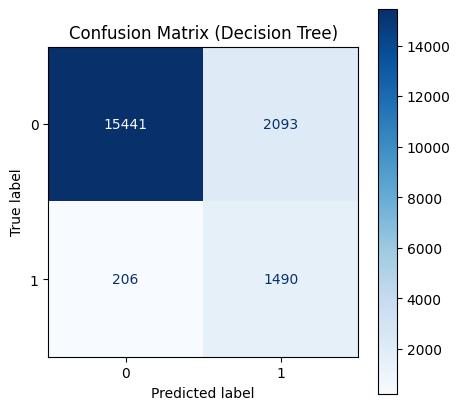


========== Random Forest Model ==========
Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.89      0.94     17534
           1       0.44      0.91      0.59      1696

    accuracy                           0.89     19230
   macro avg       0.71      0.90      0.76     19230
weighted avg       0.94      0.89      0.91     19230



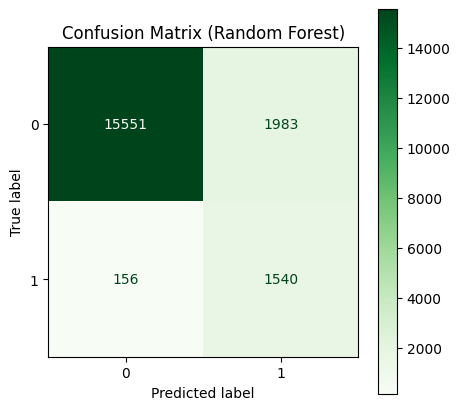

In [49]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# ==========================================================
# 1. نموذج شجرة القرار (Decision Tree)
# ==========================================================
# يمكنك تعديل هذه المعاملات (Parameters) لتحسين النموذج:
# - max_depth: أقصى عمق للشجرة (مثال: 5, 10, None)
# - min_samples_split: الحد الأدنى من العينات المطلوبة لتقسيم العقدة
# - criterion: معيار التقسيم ('gini' أو 'entropy')
dt_params = {
    'max_depth': 110,
    'min_samples_split': 5,
    'criterion': 'gini',
    'random_state': 42
}

dt_model = DecisionTreeClassifier(**dt_params)
dt_model.fit(X_train_resampled, y_train_resampled)
y_pred_dt = dt_model.predict(X_test)

print("========== Decision Tree Model ==========")
print("Classification Report:")
print(classification_report(y_test, y_pred_dt))

# حساب ورسم مصفوفة الارتباك لشجرة القرار
cm_dt = confusion_matrix(y_test, y_pred_dt)
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay(confusion_matrix=cm_dt).plot(ax=ax, cmap='Blues')
ax.set_title('Confusion Matrix (Decision Tree)')
plt.show()


# ==========================================================
# 2. نموذج الغابة العشوائية (Random Forest)
# ==========================================================
# يمكنك تعديل هذه المعاملات (Parameters) لتحسين النموذج:
# - n_estimators: عدد الأشجار في الغابة (مثال: 50, 100, 200)
# - max_depth: أقصى عمق للأشجار
# - min_samples_leaf: الحد الأدنى للعينات المطلوبة في الورقة النهائية
rf_params = {
    'n_estimators': 10,
    'max_depth': 80,
    'min_samples_leaf': 2,
    'random_state': 42,
    'n_jobs': -1
}

rf_model = RandomForestClassifier(**rf_params)
rf_model.fit(X_train_resampled, y_train_resampled)
y_pred_rf = rf_model.predict(X_test)

print("\n========== Random Forest Model ==========")
print("Classification Report:")
print(classification_report(y_test, y_pred_rf))

# حساب ورسم مصفوفة الارتباك للغابة العشوائية
cm_rf = confusion_matrix(y_test, y_pred_rf)
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay(confusion_matrix=cm_rf).plot(ax=ax, cmap='Greens')
ax.set_title('Confusion Matrix (Random Forest)')
plt.show()

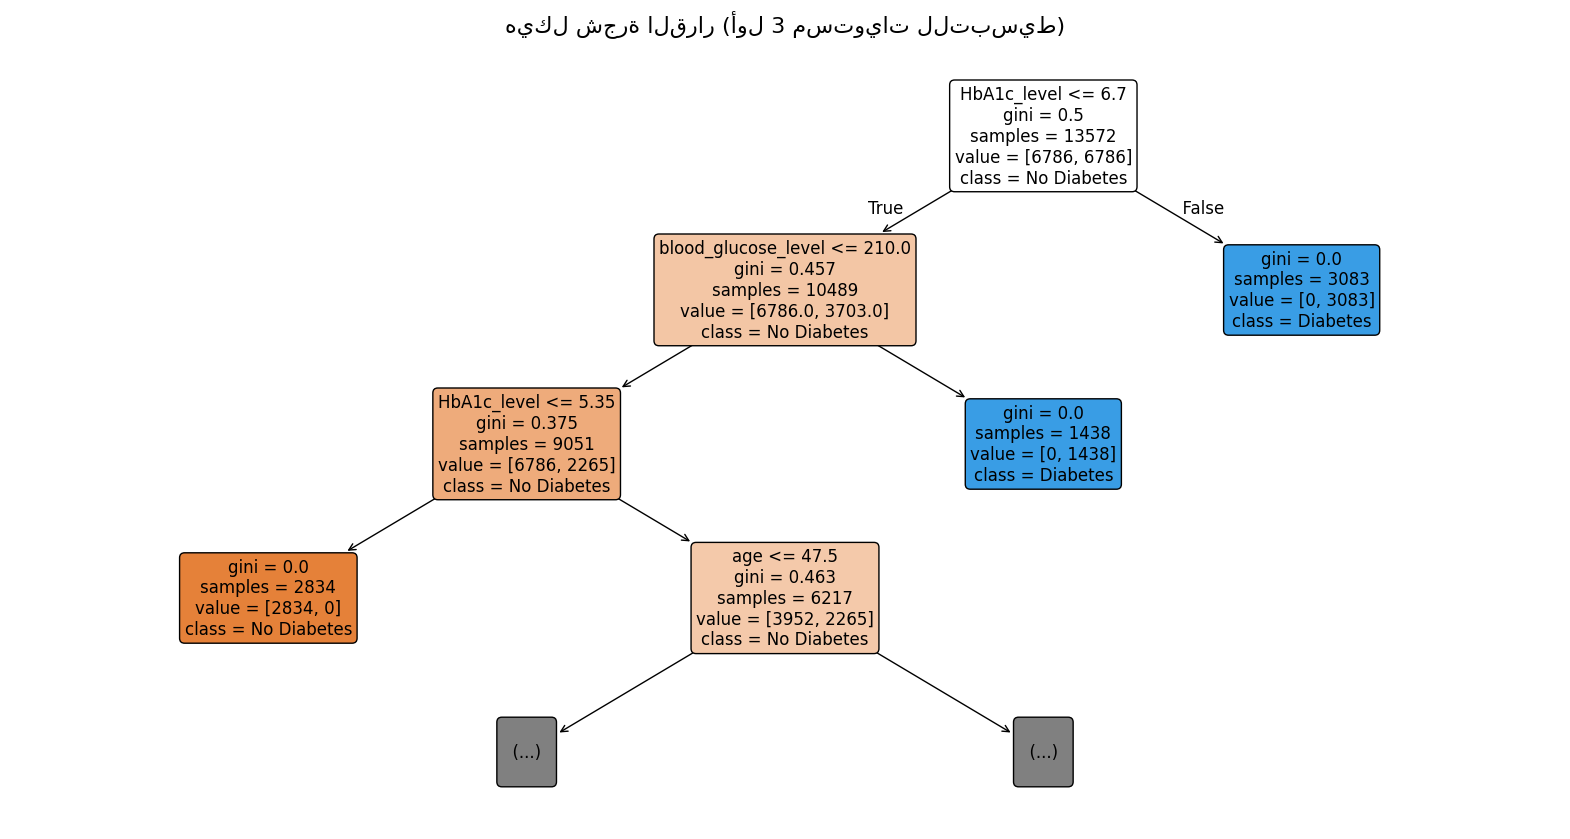

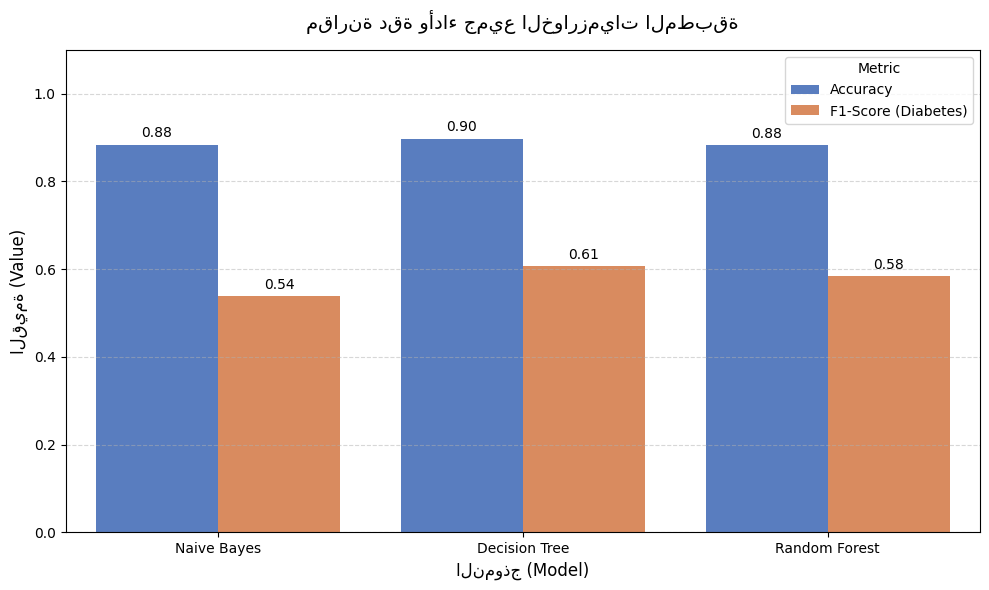

In [35]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score

# 1. حساب المقاييس لكل نموذج تم تدريبه
models_performance = {
    'Naive Bayes': {
        'Accuracy': accuracy_score(y_test, y_pred_nb),
        'F1-Score (Diabetes)': f1_score(y_test, y_pred_nb, pos_label=1)
    },
    'Decision Tree': {
        'Accuracy': accuracy_score(y_test, y_pred_dt),
        'F1-Score (Diabetes)': f1_score(y_test, y_pred_dt, pos_label=1)
    },
    'Random Forest': {
        'Accuracy': accuracy_score(y_test, y_pred_rf),
        'F1-Score (Diabetes)': f1_score(y_test, y_pred_rf, pos_label=1)
    }
}

# تحويل النتائج إلى DataFrame لسهولة الرسم
df_metrics = pd.DataFrame(models_performance).T.reset_index().rename(columns={'index': 'Model'})

# تحويل البيانات إلى تنسيق طويل (Tidy/Long format) لتناسب seaborn
df_melted = pd.melt(df_metrics, id_vars='Model', var_name='Metric', value_name='Value')

# 2. رسم المخطط البياني للمقارنة
plt.figure(figsize=(10, 6))
sns.barplot(x='Model', y='Value', hue='Metric', data=df_melted, palette='muted')

plt.title('مقارنة دقة وأداء جميع الخوارزميات المطبقة', fontsize=14, pad=15)
plt.xlabel('النموذج (Model)', fontsize=12)
plt.ylabel('القيمة (Value)', fontsize=12)
plt.ylim(0, 1.1)
plt.grid(axis='y', linestyle='--', alpha=0.5)

# إضافة القيم فوق الأعمدة لتسهيل القراءة
for p in plt.gca().patches:
    height = p.get_height()
    if height > 0:
        plt.gca().annotate(f'{height:.2f}',
                            (p.get_x() + p.get_width() / 2., height),
                            ha='center', va='center',
                            xytext=(0, 8),
                            textcoords='offset points',
                            fontsize=10)

plt.tight_layout()
plt.show()

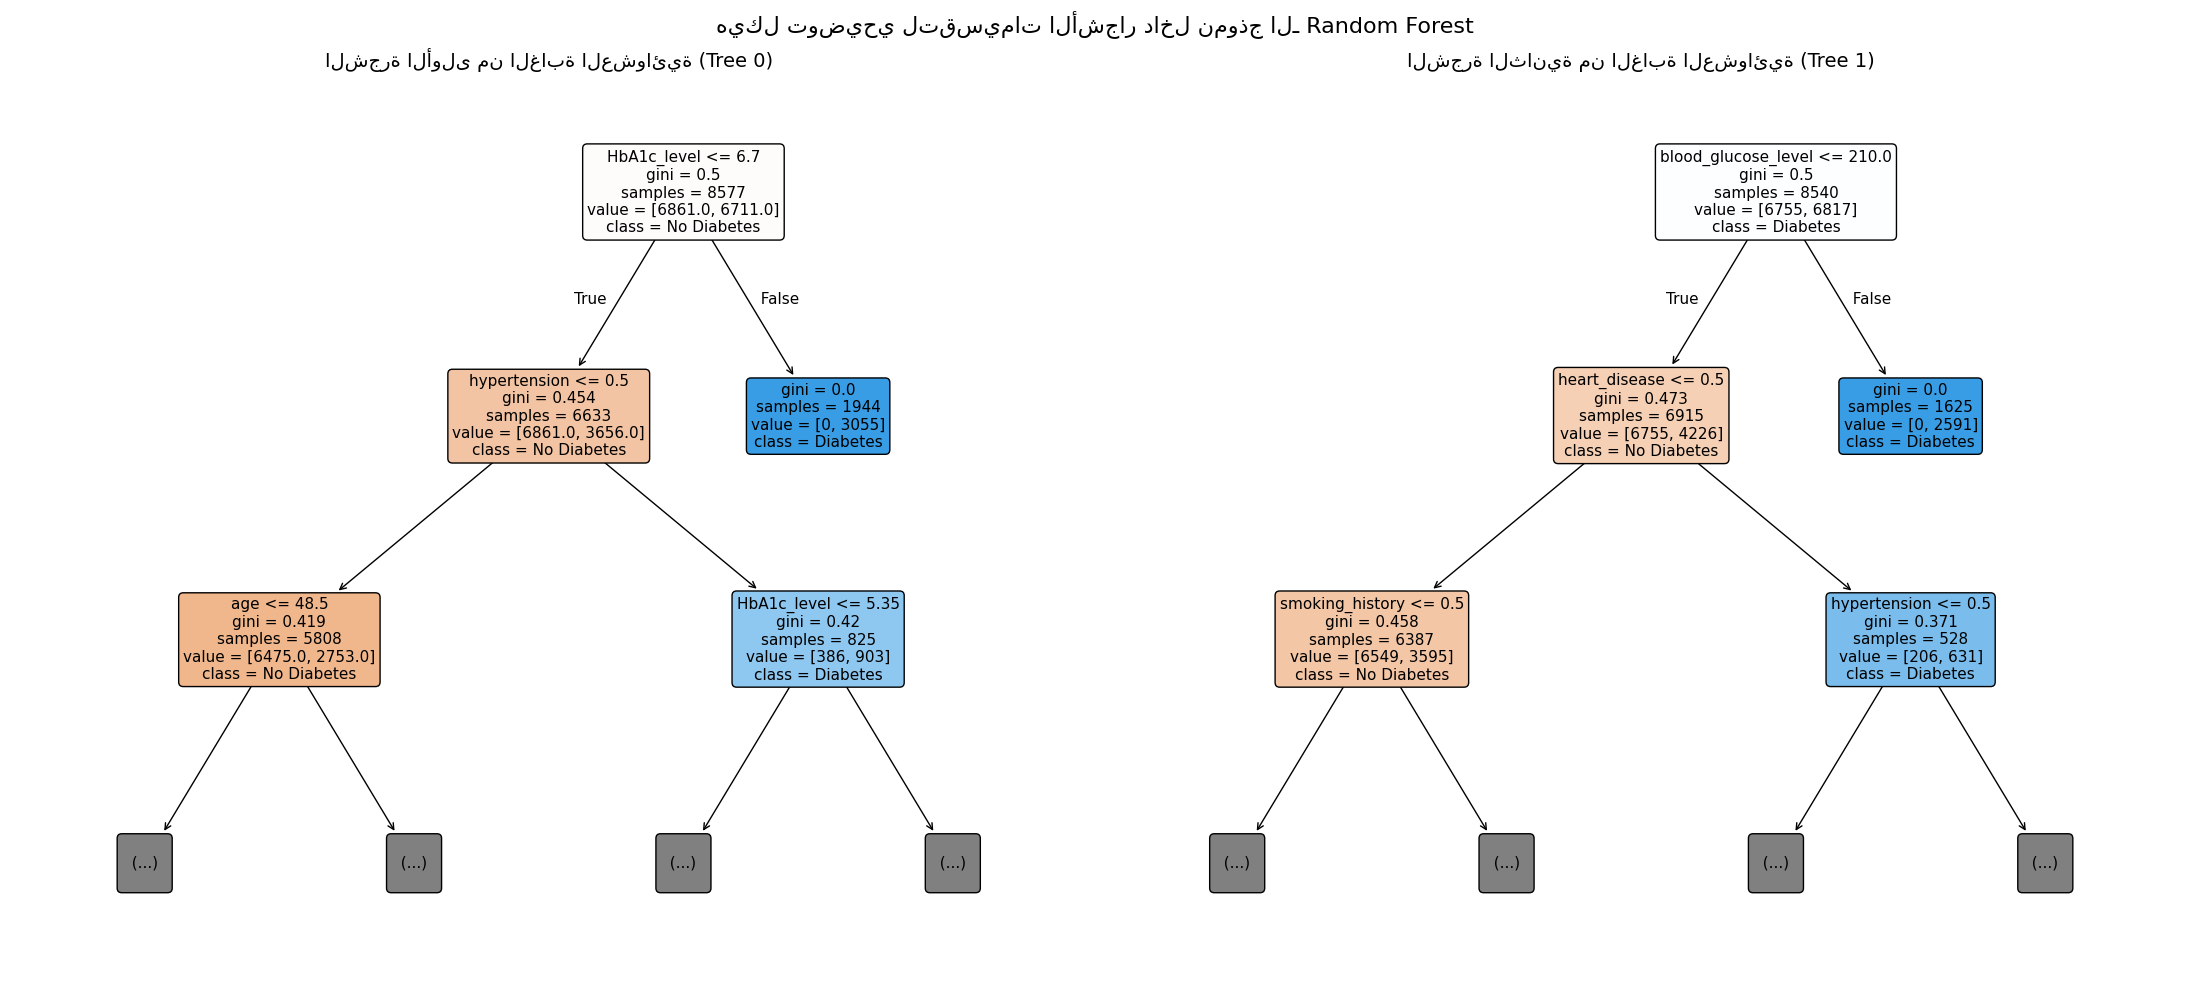

In [37]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# الغابة العشوائية تحتوي على عدة أشجار مخزنة في الميزة estimators_
# سنقوم بعرض الشجرة الأولى والثانية بحد أقصى للعمق يساوي 2 لتكون القراءة سهلة وواضحة

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(22, 10))

# رسم الشجرة الأولى
plot_tree(
    rf_model.estimators_[0],
    max_depth=2,
    feature_names=X.columns,
    class_names=['No Diabetes', 'Diabetes'],
    filled=True,
    rounded=True,
    fontsize=11,
    ax=axes[0]
)
axes[0].set_title('الشجرة الأولى من الغابة العشوائية (Tree 0)', fontsize=14, pad=10)

# رسم الشجرة الثانية لتوضيح اختلاف التقسيمات وعشوائيتها
plot_tree(
    rf_model.estimators_[1],
    max_depth=2,
    feature_names=X.columns,
    class_names=['No Diabetes', 'Diabetes'],
    filled=True,
    rounded=True,
    fontsize=11,
    ax=axes[1]
)
axes[1].set_title('الشجرة الثانية من الغابة العشوائية (Tree 1)', fontsize=14, pad=10)

plt.suptitle('هيكل توضيحي لتقسيمات الأشجار داخل نموذج الـ Random Forest', fontsize=16, y=0.98)
plt.tight_layout()
plt.show()

In [33]:
# 1. إعداد حساب غيت هاب (تأكد من تعديل الإيميل واسم المستخدم)
!git config --global user.email "saraaldenali5555@example.com"
!git config --global user.name "saraaldenali5555"

# 2. سحب المستودع باستخدام الـ Token (تأكد من وضع الرمز واسم المستودع الخاص بك)
!git clone https://colab@github.com/saraaldenali555/Machine_Learning_Training.git

# 3. الدخول إلى مجلد المستودع
%cd Machine_Learning_Training

# 4. نسخ ملف الكولاب الحالي إلى داخل مجلد المستودع (تأكد من تطابق اسم ملفك)
!cp /content/Training_Diabetes.ipynb .

# 5. تجهيز الملف وحفظه ورفعه تلقائياً
!git add .
!git commit -m "Update notebook from colab"
!git push origin main

Cloning into 'Machine_Learning_Training'...
fatal: could not read Password for 'https://colab@github.com': No such device or address
[Errno 2] No such file or directory: 'Machine_Learning_Training'
/content
cp: cannot stat '/content/Training_Diabetes.ipynb': No such file or directory
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git
